# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neilivanorencia/flyrank-ml-internship/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

Before any model is trained, this notebook checks whether the stories behind the project's signals actually show up in the data. It looks at the distributions first, then puts three claims to a test, each with a verdict, and finally tests the core assumption of a FlyRank-style CTR flag. "No" is an acceptable answer for every test.

**How to read it:** each section opens with the thinking, then a **Method** note explaining what the next code cell computes, then the output, then a **Finding** note on what it shows. Terms from the earlier notebooks (month M, month M+1, expected clicks, the target, size bands) still apply; the new ones are defined below.


## Key terms

| Term                          | Technical meaning                                                                                  | In plain words                                                                          |
| ----------------------------- | -------------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------- |
| **Signal**                    | A measurable property believed to predict the outcome                                              | A clue people think matters                                                             |
| **Verdict**                   | CONFIRMED, OPPOSITE, MIXED, or FALSE, decided by a fixed rule written before the results           | The test's answer, chosen so it cannot be bent after the fact                           |
| **Lift**                      | Rate in the group of interest ÷ rate in the comparison group                                       | How many times more often something happens in one group                                |
| **Size band**                 | Pages grouped by impressions in month M: 100 to 999, 1,000 to 9,999, and 10,000 or more            | Comparing pages of similar traffic, so size cannot fake a signal                        |
| **Sample-size floor**         | At least 50 pages on each side of a comparison                                                     | No verdict from a group too small to trust                                              |
| **Heavy tail**                | A few very large values far above the typical one                                                  | A handful of giant pages next to a long tail of small ones                              |
| **Pooled click-through rate** | Total clicks ÷ total impressions of a group                                                        | The group's real click rate, with big pages counting more                               |
| **Clicks ÷ expected**         | A group's total clicks ÷ its total expected clicks (position bin and client already accounted for) | Above 1 means the group clicks more than its position and client predict; below 1, less |
| **Buying intent**             | A keyword whose search intent is commercial or transactional                                       | Searches made to compare or buy, where ads and shopping results compete for the click   |
| **CTR flag**                  | A page with at least 500 impressions, position 20 or better, and click-through rate below 0.5%     | A stand-in for FlyRank's own low-CTR flag, whose exact rule is not in the release       |


**Method:** this cell makes sure DuckDB is version 1.1 or newer, the first version whose Hugging Face login can read the token from the environment.


In [1]:
%pip -q install "duckdb>=1.1"

## Setup

**Method, step by step:**

1. **Finds the project folder** and **reads the Hugging Face token**, as in the data contract: environment variable or `.env` file, then a Colab Secret named `HF_TOKEN`, then a typed prompt as the last resort. DuckDB reads the token from the environment, so it never appears in a query or an output.
2. **Loads the tools.** `duckdb` queries the warehouse, `pandas` and `numpy` handle the results, `scipy`'s negative binomial is the luck test, and `matplotlib` draws the one chart.
3. **Defines the months and the cache.** The same three development pairs as the data contract; June 2026 is never read. Heavy queries go through `cached()`, which saves each result once under `work/outputs/w03_cache/` and reuses it on later runs.
4. **Defines `show()` and `show_table()`**, which display every result as a titled table.


In [2]:
import getpass
import os
import sys
import tempfile
import urllib.request

import duckdb
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib import font_manager
from matplotlib.lines import Line2D
from scipy.stats import nbinom

# Locally, walk up to the project's top folder (the one holding data/raw and .env); Colab keeps its own folder.
if "google.colab" not in sys.modules:
    while not os.path.isdir("data/raw") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")


def load_env_file(path: str = ".env") -> None:
    """Copy KEY=value lines from a local .env file into the environment, keeping any value already set."""
    if not os.path.exists(path):
        return
    with open(path, encoding="utf-8-sig") as handle:
        for line in handle:
            key, sep, value = line.strip().partition("=")
            if sep and key and not key.startswith("#"):
                os.environ.setdefault(key.strip(), value.strip())


def read_colab_secret(name: str) -> str | None:
    """Return the Colab Secret called `name`, or None when it cannot be read.

    Outside Colab the import fails. On Colab the secret can be missing, not shared with this
    notebook, or the request can time out. Each case returns None so the caller can ask for the token.
    """
    try:
        from google.colab import userdata
    except ImportError:
        return None
    try:
        return userdata.get(name)
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
        return None


# Token order: environment variable or .env file, then Colab Secret, then a typed prompt as the last resort.
load_env_file()
token_source = "environment variable or .env file"
if not os.environ.get("HF_TOKEN"):
    secret = read_colab_secret("HF_TOKEN")
    token_source = "Colab Secret" if secret else "typed prompt"
    os.environ["HF_TOKEN"] = secret or getpass.getpass("Hugging Face READ token (hf_...): ")

# DuckDB reads the token from the environment, so it never appears in a query or an output.
con = duckdb.connect()
con.execute("CREATE OR REPLACE SECRET hf (TYPE huggingface, PROVIDER credential_chain)")
# Cap DuckDB's memory so large scans spill to disk, and hide its progress bars, which clutter saved outputs.
con.execute("SET memory_limit = '2GB'")
con.execute("SET preserve_insertion_order = false")
con.execute("SET enable_progress_bar = false")

REL = "hf://datasets/FlyRank/internship-warehouse"
DIM_CLIENTS = f"read_parquet('{REL}/dim_clients.parquet')"
DIM_CONTENT = f"read_parquet('{REL}/dim_content.parquet')"
QUERY_90D = f"read_parquet('{REL}/fact_content_query_90d.parquet')"
DAILY_FOOTERS = f"read_parquet('{REL}/fact_content_daily_performance/*/*.parquet')"
PAIRS = [("2026-02", "2026-03"), ("2026-03", "2026-04"), ("2026-04", "2026-05")]
DEV_MONTHS = sorted({month for pair in PAIRS for month in pair})
PANEL_MONTHS = list(pd.period_range("2025-01", "2026-05", freq="M").astype(str))
assert "2026-06" not in DEV_MONTHS + PANEL_MONTHS, "The sealed month must never be read."


def month_files(months: list[str]) -> str:
    """Return a DuckDB source that reads exactly the listed monthly partitions of the daily table."""
    paths = ", ".join(f"'{REL}/fact_content_daily_performance/month={month}/*.parquet'" for month in months)
    return f"read_parquet([{paths}])"


CACHE = "work/outputs/w03_cache"
os.makedirs(CACHE, exist_ok=True)


def cached(name: str, sql: str) -> pd.DataFrame:
    """Run a warehouse query once, save its result as Parquet in the cache folder, and reuse it afterwards.

    Repeated scans of the hosted files are slow and can hit rate limits, so every heavy query goes
    through here. Delete the cache folder to force a fresh scan.
    """
    path = f"{CACHE}/{name}.parquet"
    if not os.path.exists(path):
        # Write under a temporary name first, so an interrupted run never leaves a half-written cache file.
        con.execute(f"COPY ({sql}) TO '{path}.tmp' (FORMAT parquet)")
        os.replace(f"{path}.tmp", path)
    return con.sql(f"SELECT * FROM read_parquet('{path}')").df()


NUMBER = r"^[-+]?[\d,]*\.?\d+(?:%|x)?$"


def show_table(title: str, frame: pd.DataFrame) -> None:
    """Display a DataFrame as a titled Markdown table.

    Markdown tables look the same in Jupyter, VS Code, Colab, and GitHub, and they avoid the extra
    index row and interactive-table scripts that a plain DataFrame display adds. Columns whose
    cells are all numbers are right-aligned.
    """
    body = frame.reset_index() if frame.index.name or isinstance(frame.index, pd.MultiIndex) else frame
    cells = body.astype(str).apply(lambda col: col.str.replace("|", "\\|", regex=False).str.replace("\n", " ", regex=False))
    align = ["---:" if cells[name].str.strip().str.match(NUMBER).all() else "---" for name in cells.columns]
    lines = ["| " + " | ".join(map(str, cells.columns)) + " |", "| " + " | ".join(align) + " |"]
    lines += ["| " + " | ".join(row) + " |" for row in cells.itertuples(index=False)]
    display(Markdown(f"**{title}**\n\n" + "\n".join(lines)))


def show(title: str, rows: dict[str, object]) -> None:
    """Display a titled two-column table of measures and their values."""
    show_table(title, pd.DataFrame({"Measure": list(rows), "Value": [str(value) for value in rows.values()]}))


show("Connected to the warehouse", {
    "token read from": token_source,
    "token shown anywhere": "no (DuckDB reads it from the environment)",
    "development pairs": ", ".join(f"{a} → {b}" for a, b in PAIRS),
    "sealed pair, never read": "2026-05 → 2026-06",
    "cache folder": CACHE,
})

**Connected to the warehouse**

| Measure | Value |
| --- | --- |
| token read from | Colab Secret |
| token shown anywhere | no (DuckDB reads it from the environment) |
| development pairs | 2026-02 → 2026-03, 2026-03 → 2026-04, 2026-04 → 2026-05 |
| sealed pair, never read | 2026-05 → 2026-06 |
| cache folder | work/outputs/w03_cache |

## Data

The signals are tested on the same three development pairs as the data contract, rebuilt with its rules. June 2026 stays sealed.


**Method:** this cell builds the page-month table for February to May 2026 (one row per page per month, position pieces only from days with a valid position, GA4 numbers only where `ga4_data_available IS TRUE`), now including GA4 engaged sessions for the engagement reason code. Each month is scanned once and cached. It also reads each client's search-history start date and each page's content type, search intent, and latest optimization date.


In [3]:
# One row per page per month, with GA4 engaged sessions added for the engagement reason code.
PAGE_MONTH_SQL = """
    SELECT '{month}' AS month, client_hash_id, content_hash_id,
           SUM(gsc_impressions) AS impressions,
           SUM(gsc_clicks) AS clicks,
           SUM(CASE WHEN gsc_avg_position >= 1 THEN gsc_impressions ELSE 0 END) AS position_impressions,
           SUM(CASE WHEN gsc_avg_position >= 1 THEN gsc_sum_position ELSE 0 END) AS sum_position,
           SUM(CASE WHEN gsc_avg_position >= 1 THEN gsc_sum_position * gsc_avg_position ELSE 0 END) AS sum_position_sq,
           SUM(CASE WHEN gsc_avg_position >= 1 THEN 0 ELSE gsc_clicks END) AS clicks_without_position,
           COUNT(*) AS days_with_impressions,
           SUM(CASE WHEN ga4_data_available IS TRUE THEN ga4_sessions ELSE 0 END) AS ga4_sessions,
           SUM(CASE WHEN ga4_data_available IS TRUE THEN ga4_engaged_sessions ELSE 0 END) AS ga4_engaged_sessions
    FROM {source}
    WHERE gsc_impressions > 0
    GROUP BY client_hash_id, content_hash_id"""
page_months = pd.concat([
    cached(f"page_month_v3_{month}", PAGE_MONTH_SQL.format(month=month, source=month_files([month]))) for month in DEV_MONTHS
], ignore_index=True)
assert not page_months.duplicated(["month", "content_hash_id"]).any(), "A page appears twice in one month."

clients = con.sql(f"SELECT client_hash_id, gsc_data_start FROM {DIM_CLIENTS}").df()
clients["gsc_data_start"] = pd.to_datetime(clients["gsc_data_start"])
content = con.sql(f"SELECT content_hash_id, content_type, main_intent, last_optimized_date FROM {DIM_CONTENT}").df()
show_table("Inputs loaded", pd.DataFrame({
    "Rows": [f"{len(page_months):,}", f"{len(clients):,}", f"{len(content):,}"],
    "What it is": ["Page-months, February to May 2026", "Clients with their search-history start date",
                   "Pages with content type, search intent, and latest optimization date"],
}, index=pd.Index(["page_months", "clients", "content"], name="Table")))

**Inputs loaded**

| Table | Rows | What it is |
| --- | ---: | --- |
| page_months | 762,967 | Page-months, February to May 2026 |
| clients | 104 | Clients with their search-history start date |
| content | 519,606 | Pages with content type, search intent, and latest optimization date |

**Method:** this cell applies the data contract's rules to each development pair (impressions in both months, client history covering all of month M, a valid position in both months, not optimized during the pair). For each month it computes the impression-weighted position, its daily spread, expected clicks from the fine position bins and from the five tiers (both client-scaled), and whether the page fell short by the locked rule: clicks at most half of expected, with negative binomial p below 0.05. The spread factor α is estimated exactly as the data contract does (one estimate per pair from pages whose position barely moved, the median rounded to three decimals), so every notebook shares one target. The month M+1 version of the rule is the target.


In [4]:
# Rules and bins exactly as in the data contract; the spread factor is estimated below with its method.
BIN_EDGES = [1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5, 20.5, 50.5]
BIN_NAMES = [str(position) for position in range(1, 11)] + ["11-20", "21-50", "50+"]


def position_bin(position: pd.Series) -> pd.Series:
    """Return each page's position bin: exact rank up to 10, then 11-20, 21-50, and 50+."""
    return pd.Series(np.array(BIN_NAMES)[np.searchsorted(BIN_EDGES, position, side="right")], index=position.index)


def position_tier(position: pd.Series) -> pd.Series:
    """Return the five tiers used by the earlier score: below 3, below 10, below 20, below 50, and 50 or beyond."""
    tiers = np.select([position < 3, position < 10, position < 20, position < 50], ["top_3", "page_1", "striking", "page_3_5"], "deep")
    return pd.Series(tiers, index=position.index)


def client_aware_expected(frame: pd.DataFrame, clicks: str, impressions: str, group: pd.Series) -> pd.Series:
    """Return expected clicks from each group's pooled click rate, scaled by the page's client factor (+1 on both sides)."""
    rate = frame[clicks].groupby(group).sum() / frame[impressions].groupby(group).sum()
    expected = frame[impressions] * group.map(rate)
    by_client = frame.assign(_expected=expected).groupby("client_hash_id")
    factor = (by_client[clicks].sum() + 1) / (by_client["_expected"].sum() + 1)
    return expected * frame["client_hash_id"].map(factor)


def covered_clients(month_m: str) -> pd.Series:
    """Return the clients whose search history starts on or before the first day of month M."""
    return clients.loc[clients["gsc_data_start"] <= pd.Timestamp(f"{month_m}-01"), "client_hash_id"]


def add_month_measures(rows: pd.DataFrame, suffix: str) -> pd.DataFrame:
    """Add position, its spread, click-through, and both expectations for one month."""
    impressions, clicks = rows[f"impressions_{suffix}"], rows[f"clicks_{suffix}"]
    rows[f"position_{suffix}"] = rows[f"sum_position_{suffix}"] / rows[f"position_impressions_{suffix}"]
    spread = rows[f"sum_position_sq_{suffix}"] / rows[f"position_impressions_{suffix}"] - rows[f"position_{suffix}"] ** 2
    rows[f"position_volatility_{suffix}"] = np.sqrt(spread.clip(lower=0))
    rows[f"ctr_{suffix}"] = clicks / impressions
    rows[f"expected_bins_{suffix}"] = client_aware_expected(rows, f"clicks_{suffix}", f"impressions_{suffix}", position_bin(rows[f"position_{suffix}"]))
    rows[f"expected_tier_{suffix}"] = client_aware_expected(rows, f"clicks_{suffix}", f"impressions_{suffix}", position_tier(rows[f"position_{suffix}"]))
    return rows


def add_luck_test(rows: pd.DataFrame, suffix: str) -> pd.DataFrame:
    """Add the negative binomial luck test and the locked shortfall rule for one month."""
    clicks, expected = rows[f"clicks_{suffix}"], rows[f"expected_bins_{suffix}"]
    rows[f"p_{suffix}"] = nbinom.cdf(clicks, 1 / ALPHA, 1 / (1 + ALPHA * expected))
    rows[f"shortfall_{suffix}"] = (rows[f"p_{suffix}"] < 0.05) & (clicks <= 0.5 * expected)
    return rows


def build_pair(month_m: str, month_next: str) -> pd.DataFrame:
    """Return one month pair's eligible rows with both months' measures and the locked target."""
    keys = ["client_hash_id", "content_hash_id"]
    first = page_months[page_months["month"] == month_m].set_index(keys)
    second = page_months[page_months["month"] == month_next].set_index(keys)
    rows = first.join(second, lsuffix="_m", rsuffix="_next", how="inner").reset_index()
    start, end = pd.Timestamp(f"{month_m}-01"), pd.Timestamp(f"{month_next}-01") + pd.offsets.MonthEnd(0)
    rows = rows[rows["client_hash_id"].isin(covered_clients(month_m))]
    rows = rows[(rows["position_impressions_m"] > 0) & (rows["position_impressions_next"] > 0)]
    rows = rows.merge(content, on="content_hash_id", how="left")
    rows = rows[~pd.to_datetime(rows["last_optimized_date"]).between(start, end)].copy()
    rows = add_month_measures(add_month_measures(rows, "m"), "next")
    rows["pair_end"] = end
    return rows.reset_index(drop=True)


def stable_pages(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Return pages whose position moved less than one place, and each one's expected share of clicks in month M+1.

    The expected share corrects for the overall change in click rate between the two months.
    """
    stable = frame[(frame["position_next"] - frame["position_m"]).abs() < 1]
    shift = (stable["clicks_next"].sum() / stable["impressions_next"].sum()) / (stable["clicks_m"].sum() / stable["impressions_m"].sum())
    share = shift * stable["impressions_next"] / (stable["impressions_m"] + shift * stable["impressions_next"])
    return stable, share



def spread_factor(frame: pd.DataFrame) -> float:
    """Return the method-of-moments estimate of the negative binomial spread factor alpha.

    For pages with a stable position, the gap between month-M+1 clicks and the clicks their month-M rate
    predicts has variance (Poisson part) + alpha x (squared clicks). Pooling the excess over the Poisson
    part across pages gives alpha.
    """
    stable, share = stable_pages(frame)
    scale = share / (1 - share)
    gap = stable["clicks_next"] - scale * stable["clicks_m"]
    excess = (gap ** 2 - stable["clicks_next"] - scale ** 2 * stable["clicks_m"]).sum()
    squared = ((stable["clicks_next"] ** 2 - stable["clicks_next"]) + scale ** 2 * (stable["clicks_m"] ** 2 - stable["clicks_m"])).sum()
    return float(excess / squared)



pairs = {f"{month_m} → {month_next}": build_pair(month_m, month_next) for month_m, month_next in PAIRS}
ALPHA = round(float(np.median([spread_factor(rows) for rows in pairs.values()])), 3)
for rows in pairs.values():
    add_luck_test(add_luck_test(rows, "m"), "next")
    rows["target"] = rows["shortfall_next"]
    rows["missed_next"] = (rows["expected_bins_next"] - rows["clicks_next"]).clip(lower=0).where(rows["target"], 0)
show_table(f"Development pairs with the locked target (α = {ALPHA:.3f})", pd.DataFrame({
    "Rows": [f"{len(rows):,}" for rows in pairs.values()],
    "Positives": [f"{rows['target'].sum():,}" for rows in pairs.values()],
    "Base rate": [f"{rows['target'].mean():.1%}" for rows in pairs.values()],
}, index=pd.Index(list(pairs), name="Pair")))

**Development pairs with the locked target (α = 0.039)**

| Pair | Rows | Positives | Base rate |
| --- | ---: | ---: | ---: |
| 2026-02 → 2026-03 | 114,972 | 8,465 | 7.4% |
| 2026-03 → 2026-04 | 155,707 | 10,031 | 6.4% |
| 2026-04 → 2026-05 | 157,530 | 6,525 | 4.1% |

**Finding:** the three pairs hold 114,972, 155,707, and 157,530 rows with 8,465, 10,031, and 6,525 real shortfalls (base rates 7.4%, 6.4%, and 4.1%), and the spread factor comes out at 0.039: the same rows and target as the data contract.


## 1. Distributions

Web traffic is almost always heavy-tailed, and that decides how every test below has to be built.

**Method:** this cell describes the month-M fields across every development row: the share of zeros, the percentiles, and the ratio of the mean to the median (far above 1 means a heavy tail). It then measures how much of all impressions and clicks the top 1% of pages hold, and how the rows split by search intent.


In [5]:
# Percentiles and tail weight of the month-M fields, across every row of the three pairs.
stacked = pd.concat(pairs.values(), ignore_index=True)
FIELDS = {"impressions_m": "Impressions", "clicks_m": "Clicks", "ctr_m": "Click-through rate",
          "position_m": "Position", "position_volatility_m": "Daily position spread"}
QUANTILES = [0.25, 0.5, 0.75, 0.9, 0.99]


def describe(values: pd.Series, as_percent: bool) -> dict[str, str]:
    """Return the share of zeros, the main percentiles, the maximum, and the mean-to-median ratio of one field."""
    fmt = "{:.2%}".format if as_percent else "{:,.1f}".format
    q = values.quantile(QUANTILES)
    out = {"Zero": f"{(values == 0).mean():.1%}"}
    out.update({label: fmt(q[level]) for level, label in zip(QUANTILES, ["25th", "Median", "75th", "90th", "99th"], strict=True)})
    out["Max"] = fmt(values.max())
    out["Mean ÷ median"] = f"{values.mean() / q[0.5]:.1f}x" if q[0.5] > 0 else "median is 0"
    return out


show_table(f"Month-M fields across all {len(stacked):,} development rows",
           pd.DataFrame({label: describe(stacked[field], field == "ctr_m") for field, label in FIELDS.items()}).T.rename_axis("Field"))


def top_share(values: pd.Series, top: float = 0.01) -> float:
    """Return the share of the total held by the largest `top` fraction of rows."""
    ordered = values.sort_values(ascending=False)
    return float(ordered.iloc[: max(1, int(len(ordered) * top))].sum() / ordered.sum())


intents = stacked["main_intent"].fillna("unknown").value_counts()
show("How concentrated the traffic is", {
    "impressions held by the top 1% of rows": f"{top_share(stacked['impressions_m']):.1%}",
    "clicks held by the top 1% of rows": f"{top_share(stacked['clicks_m']):.1%}",
    **{f"rows with {intent} intent": f"{count:,} ({count / len(stacked):.1%})" for intent, count in intents.items()},
})

**Month-M fields across all 428,209 development rows**

| Field | Zero | 25th | Median | 75th | 90th | 99th | Max | Mean ÷ median |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | --- |
| Impressions | 0.0% | 33.0 | 203.0 | 1,075.0 | 3,930.0 | 21,723.6 | 617,124.0 | 8.0x |
| Clicks | 60.0% | 0.0 | 0.0 | 2.0 | 10.0 | 75.0 | 5,668.0 | median is 0 |
| Click-through rate | 60.0% | 0.00% | 0.00% | 0.23% | 0.63% | 4.76% | 100.00% | median is 0 |
| Position | 0.0% | 5.7 | 9.4 | 22.1 | 42.2 | 78.0 | 337.0 | 1.8x |
| Daily position spread | 4.5% | 1.9 | 4.7 | 11.2 | 19.5 | 34.7 | 192.9 | 1.7x |

**How concentrated the traffic is**

| Measure | Value |
| --- | --- |
| impressions held by the top 1% of rows | 24.5% |
| clicks held by the top 1% of rows | 34.1% |
| rows with informational intent | 251,160 (58.7%) |
| rows with transactional intent | 80,007 (18.7%) |
| rows with commercial intent | 69,769 (16.3%) |
| rows with unknown intent | 26,116 (6.1%) |
| rows with navigational intent | 1,157 (0.3%) |

**Finding:** every traffic field is heavy-tailed. Across the 428,209 development rows the median page had 203 impressions but the largest had 617,124, and the mean is 8.0 times the median. 60.0% of rows earned no click at all, so the median click count and click-through rate are both 0; only a quarter of rows click through at 0.23% or more. The top 1% of rows hold 24.5% of all impressions and 34.1% of all clicks. The median page sits at position 9.4 and its daily position moves by a typical 4.7 places. By intent, 58.7% of rows are informational, 18.7% transactional, 16.3% commercial, 6.1% unknown, and 0.3% navigational. These tails are why every test below compares pages inside size bands and uses pooled rates instead of averages of page rates.


## 2. Signal test #1 / #2 / #3 (verdict each)

Every test follows the same shape: the claim in one sentence, a table on a defined slice with the number of pages beside every rate, and a verdict.

**The verdict rule, fixed before any result:** each comparison cell gives a ratio (the group of interest against the comparison group). Only cells with at least 50 pages on both sides count. A ratio of 1.1 or more counts as "higher", 0.9 or less as "lower", anything in between as "no difference". **CONFIRMED** means every counted cell moves the way the claim says; **OPPOSITE** means every counted cell moves the other way; **FALSE** means no counted cell shows a difference; **MIXED** is everything else. Pages under 100 impressions are left out of the size-banded tests: at that size real shortfalls are almost impossible to detect (the leakage check measured 0.1% to 0.3%), so their rates say nothing.

**Method:** this cell defines the size bands, the floor, and the verdict rule as code, so every test applies them identically.


In [6]:
# The size bands, the sample-size floor, and the verdict rule shared by every test.
SIZE_EDGES = [100, 1_000, 10_000, np.inf]
SIZE_NAMES = ["100 to 999", "1,000 to 9,999", "10,000 or more"]
FLOOR = 50


def size_band(impressions: pd.Series) -> pd.Series:
    """Return each page's size band from its impressions in month M (pages under 100 get no band)."""
    return pd.cut(impressions, SIZE_EDGES, right=False, labels=SIZE_NAMES)


def verdict(effects: list[float], claim: str) -> str:
    """Return the verdict from effect ratios of cells that passed the floor; `claim` is 'higher' or 'lower'."""
    if not effects:
        return "INSUFFICIENT DATA"
    higher, lower = [e >= 1.1 for e in effects], [e <= 0.9 for e in effects]
    agree, against = (higher, lower) if claim == "higher" else (lower, higher)
    if all(agree):
        return "CONFIRMED"
    if all(against):
        return "OPPOSITE"
    if not any(agree) and not any(against):
        return "FALSE"
    return "MIXED"


def rate_cells(name: str, cell: pd.DataFrame, group_of_interest: pd.Series, labels: tuple[str, str]) -> tuple[dict, float | None]:
    """Compare next-month shortfall rates of two groups in one cell; return a table row and the ratio if the floor is met."""
    yes, no = cell[group_of_interest], cell[~group_of_interest]
    rate_yes, rate_no = yes["target"].mean(), no["target"].mean()
    enough = len(yes) >= FLOOR and len(no) >= FLOOR and rate_no > 0
    row = {f"Pages, {labels[0]}": f"{len(yes):,}", f"Next-month rate, {labels[0]}": f"{rate_yes:.1%}",
           f"Pages, {labels[1]}": f"{len(no):,}", f"Next-month rate, {labels[1]}": f"{rate_no:.1%}",
           "Lift": f"{rate_yes / rate_no:.1f}x" if enough else "below floor"}
    return row, (rate_yes / rate_no if enough else None)

### Signal #1: shortfalls persist

**Claim:** a page that falls clearly short of its expected clicks this month is far more likely to fall short again next month, at the same size. The whole project rests on this: if shortfalls did not persist, ranking by this month's shortfall would be pointless.

**Method:** this cell splits each size band of each pair into pages that fell short in month M (by the same rule as the target) and pages that did not, and compares how often each group falls short in month M+1.


In [7]:
# Next-month shortfall rate for pages short in month M against pages that were not, within each size band.
records, effects = [], []
for name, rows in pairs.items():
    band = size_band(rows["impressions_m"])
    for size in SIZE_NAMES:
        cell = rows[band == size]
        row, effect = rate_cells(name, cell, cell["shortfall_m"], ("short in M", "not short in M"))
        records.append({"Pair": name, "Impressions in month M": size, **row})
        effects += [effect] if effect is not None else []
persist_verdict = verdict(effects, "higher")
show_table("Signal #1: does a shortfall this month predict one next month?",
           pd.DataFrame(records).set_index(["Pair", "Impressions in month M"]))
show("Signal #1 verdict", {"claim": "shortfalls persist into the next month", "cells passing the floor": f"{len(effects)} of {len(records)}",
                           "verdict": persist_verdict})

**Signal #1: does a shortfall this month predict one next month?**

| Pair | Impressions in month M | Pages, short in M | Next-month rate, short in M | Pages, not short in M | Next-month rate, not short in M | Lift |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| 2026-02 → 2026-03 | 100 to 999 | 382 | 26.7% | 37,805 | 3.2% | 8.4x |
| 2026-02 → 2026-03 | 1,000 to 9,999 | 6,472 | 51.1% | 21,259 | 13.2% | 3.9x |
| 2026-02 → 2026-03 | 10,000 or more | 917 | 75.0% | 2,313 | 10.5% | 7.1x |
| 2026-03 → 2026-04 | 100 to 999 | 415 | 20.0% | 54,861 | 1.7% | 11.8x |
| 2026-03 → 2026-04 | 1,000 to 9,999 | 8,662 | 43.9% | 30,355 | 9.8% | 4.5x |
| 2026-03 → 2026-04 | 10,000 or more | 2,029 | 76.9% | 3,848 | 14.6% | 5.3x |
| 2026-04 → 2026-05 | 100 to 999 | 459 | 7.6% | 54,374 | 1.0% | 7.8x |
| 2026-04 → 2026-05 | 1,000 to 9,999 | 6,891 | 32.6% | 22,779 | 8.5% | 3.8x |
| 2026-04 → 2026-05 | 10,000 or more | 1,850 | 69.9% | 4,103 | 10.4% | 6.7x |

**Signal #1 verdict**

| Measure | Value |
| --- | --- |
| claim | shortfalls persist into the next month |
| cells passing the floor | 9 of 9 |
| verdict | CONFIRMED |

**Finding:** **CONFIRMED** in all 9 cells. A page that fell short this month is 3.8 to 11.8 times as likely to fall short again next month as a page of the same size that did not. Among the largest pages (10,000 or more impressions), 69.9% to 76.9% of those short in month M were short again, against 10.4% to 14.6% of the rest. The assumption under the whole project holds: this month's real shortfalls point at next month's.


### Signal #2: search intent changes click-through at the same position

**Claim:** at the same position, keywords with buying intent (commercial or transactional) earn fewer clicks than informational ones, because ads and shopping results compete for the click. If true, a single click-rate curve per position mislabels whole groups of pages, and a learned expectation has a clear job.

**Method:** this cell takes pages with known intent at positions 1 to 20, groups them by position (1 to 3, 4 to 10, 11 to 20) and intent, and reports the pooled click-through rate and clicks ÷ expected. The second measure already accounts for exact position and client, so a gap there is intent's own effect. The verdict compares buying intent with informational intent on clicks ÷ expected.


In [8]:
# Pooled click-through and clicks ÷ expected by intent, inside three position groups.
INTENT_GROUP = {"commercial": "Buying", "transactional": "Buying", "informational": "Informational", "navigational": "Navigational"}
POSITION_EDGES, POSITION_NAMES = [0, 3.5, 10.5, 20.5], ["1 to 3", "4 to 10", "11 to 20"]
records, effects = [], []
for name, rows in pairs.items():
    known = rows[rows["main_intent"].notna() & (rows["position_m"] < 20.5)]
    summary = known.groupby([pd.cut(known["position_m"], POSITION_EDGES, labels=POSITION_NAMES).rename("position"),
                             known["main_intent"].map(INTENT_GROUP).rename("intent")], observed=True).agg(
        pages=("content_hash_id", "size"), clicks=("clicks_m", "sum"), impressions=("impressions_m", "sum"),
        expected=("expected_bins_m", "sum"))
    summary["ratio"] = summary["clicks"] / summary["expected"]
    for (position, intent), cell in summary.iterrows():
        records.append({"Pair": name, "Position": position, "Intent": intent, "Pages": f"{cell['pages']:,.0f}",
                        "Pooled click-through": f"{cell['clicks'] / cell['impressions']:.2%}", "Clicks ÷ expected": f"{cell['ratio']:.2f}"})
    for position in POSITION_NAMES:
        if (position, "Buying") in summary.index and (position, "Informational") in summary.index:
            buying, informational = summary.loc[(position, "Buying")], summary.loc[(position, "Informational")]
            if min(buying["pages"], informational["pages"]) >= FLOOR:
                effects.append(buying["ratio"] / informational["ratio"])
intent_verdict = verdict(effects, "lower")
show_table("Signal #2: click-through by search intent at the same position",
           pd.DataFrame(records).set_index(["Pair", "Position", "Intent"]))
show("Signal #2 verdict", {"claim": "buying intent clicks less than informational at the same position",
                           "cells passing the floor": f"{len(effects)} of {len(POSITION_NAMES) * len(pairs)}", "verdict": intent_verdict})

**Signal #2: click-through by search intent at the same position**

| Pair | Position | Intent | Pages | Pooled click-through | Clicks ÷ expected |
| --- | --- | --- | ---: | ---: | ---: |
| 2026-02 → 2026-03 | 1 to 3 | Buying | 6,452 | 0.44% | 1.20 |
| 2026-02 → 2026-03 | 1 to 3 | Informational | 6,292 | 0.37% | 1.00 |
| 2026-02 → 2026-03 | 1 to 3 | Navigational | 5 | 0.26% | 0.59 |
| 2026-02 → 2026-03 | 4 to 10 | Buying | 20,031 | 0.30% | 1.00 |
| 2026-02 → 2026-03 | 4 to 10 | Informational | 30,225 | 0.33% | 1.00 |
| 2026-02 → 2026-03 | 4 to 10 | Navigational | 229 | 0.34% | 1.03 |
| 2026-02 → 2026-03 | 11 to 20 | Buying | 8,079 | 0.35% | 0.97 |
| 2026-02 → 2026-03 | 11 to 20 | Informational | 12,917 | 0.28% | 0.76 |
| 2026-02 → 2026-03 | 11 to 20 | Navigational | 52 | 0.45% | 1.20 |
| 2026-03 → 2026-04 | 1 to 3 | Buying | 6,032 | 0.43% | 1.21 |
| 2026-03 → 2026-04 | 1 to 3 | Informational | 7,834 | 0.37% | 1.02 |
| 2026-03 → 2026-04 | 1 to 3 | Navigational | 13 | 0.19% | 0.38 |
| 2026-03 → 2026-04 | 4 to 10 | Buying | 24,005 | 0.30% | 1.02 |
| 2026-03 → 2026-04 | 4 to 10 | Informational | 40,857 | 0.32% | 1.00 |
| 2026-03 → 2026-04 | 4 to 10 | Navigational | 237 | 0.33% | 0.89 |
| 2026-03 → 2026-04 | 11 to 20 | Buying | 9,700 | 0.31% | 0.91 |
| 2026-03 → 2026-04 | 11 to 20 | Informational | 16,669 | 0.31% | 0.85 |
| 2026-03 → 2026-04 | 11 to 20 | Navigational | 44 | 0.37% | 0.97 |
| 2026-04 → 2026-05 | 1 to 3 | Buying | 2,953 | 0.49% | 1.27 |
| 2026-04 → 2026-05 | 1 to 3 | Informational | 4,283 | 0.42% | 1.07 |
| 2026-04 → 2026-05 | 1 to 3 | Navigational | 11 | 0.18% | 0.25 |
| 2026-04 → 2026-05 | 4 to 10 | Buying | 21,664 | 0.30% | 1.04 |
| 2026-04 → 2026-05 | 4 to 10 | Informational | 41,315 | 0.32% | 1.03 |
| 2026-04 → 2026-05 | 4 to 10 | Navigational | 184 | 0.43% | 0.98 |
| 2026-04 → 2026-05 | 11 to 20 | Buying | 10,285 | 0.33% | 0.90 |
| 2026-04 → 2026-05 | 11 to 20 | Informational | 19,107 | 0.32% | 0.82 |
| 2026-04 → 2026-05 | 11 to 20 | Navigational | 51 | 0.39% | 0.92 |

**Signal #2 verdict**

| Measure | Value |
| --- | --- |
| claim | buying intent clicks less than informational at the same position |
| cells passing the floor | 9 of 9 |
| verdict | MIXED |

**Finding:** **MIXED**, and never in the direction of the claim. Buying intent does not click less at the same position: once position and client are accounted for, it clicks about 1.2 times as much as informational intent at positions 1 to 3 in all three pairs (clicks ÷ expected 1.20 against 1.00, 1.21 against 1.02, and 1.27 against 1.07), the same at positions 4 to 10 (within 4%), and somewhat more at positions 11 to 20 (0.97 against 0.76, 0.91 against 0.85, and 0.90 against 0.82). The popular story that ads take the clicks on buying searches does not show here. Intent still moves the expected click rate, which is what a learned expectation can use.


### Signal #3: an unstable rank leads to a shortfall

**Claim:** pages whose daily position moves a lot within the month fall short next month more often than stable pages of the same size. This tests the one feature that only daily data makes possible.

**Method:** this cell groups pages by their daily position spread in month M (stable: under 2 places; moderate: 2 to 5; unstable: 5 or more) and compares the next-month shortfall rate of unstable and stable pages within each size band.


In [9]:
# Next-month shortfall rate by how much the daily position moved in month M, within each size band.
records, effects = [], []
for name, rows in pairs.items():
    band = size_band(rows["impressions_m"])
    spread = rows["position_volatility_m"]
    for size in SIZE_NAMES:
        in_band = band == size
        cell = rows[in_band & ((spread < 2) | (spread >= 5))]
        row, effect = rate_cells(name, cell, cell["position_volatility_m"] >= 5, ("unstable", "stable"))
        moderate = rows[in_band & (spread >= 2) & (spread < 5)]
        records.append({"Pair": name, "Impressions in month M": size, **row,
                        "Pages, moderate": f"{len(moderate):,}", "Next-month rate, moderate": f"{moderate['target'].mean():.1%}"})
        effects += [effect] if effect is not None else []
volatility_verdict = verdict(effects, "higher")
show_table("Signal #3: does an unstable rank predict a shortfall next month?",
           pd.DataFrame(records).set_index(["Pair", "Impressions in month M"]))
show("Signal #3 verdict", {"claim": "unstable pages fall short more often", "cells passing the floor": f"{len(effects)} of {len(records)}",
                           "verdict": volatility_verdict})

**Signal #3: does an unstable rank predict a shortfall next month?**

| Pair | Impressions in month M | Pages, unstable | Next-month rate, unstable | Pages, stable | Next-month rate, stable | Lift | Pages, moderate | Next-month rate, moderate |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 2026-02 → 2026-03 | 100 to 999 | 18,922 | 2.8% | 6,662 | 4.4% | 0.6x | 12,603 | 3.9% |
| 2026-02 → 2026-03 | 1,000 to 9,999 | 3,411 | 27.4% | 15,866 | 19.7% | 1.4x | 8,454 | 24.3% |
| 2026-02 → 2026-03 | 10,000 or more | 132 | 44.7% | 2,585 | 25.7% | 1.7x | 513 | 40.4% |
| 2026-03 → 2026-04 | 100 to 999 | 35,197 | 1.3% | 7,326 | 3.3% | 0.4x | 12,753 | 2.4% |
| 2026-03 → 2026-04 | 1,000 to 9,999 | 9,112 | 18.8% | 16,885 | 16.5% | 1.1x | 13,020 | 17.6% |
| 2026-03 → 2026-04 | 10,000 or more | 592 | 42.1% | 3,896 | 32.7% | 1.3x | 1,389 | 43.2% |
| 2026-04 → 2026-05 | 100 to 999 | 36,770 | 0.7% | 5,425 | 2.1% | 0.4x | 12,638 | 1.4% |
| 2026-04 → 2026-05 | 1,000 to 9,999 | 9,226 | 12.9% | 10,585 | 13.7% | 0.9x | 9,859 | 15.5% |
| 2026-04 → 2026-05 | 10,000 or more | 733 | 40.7% | 4,062 | 22.3% | 1.8x | 1,158 | 44.7% |

**Signal #3 verdict**

| Measure | Value |
| --- | --- |
| claim | unstable pages fall short more often |
| cells passing the floor | 9 of 9 |
| verdict | MIXED |

**Finding:** **MIXED**, and the split follows page size. Among small pages (100 to 999 impressions), unstable pages fall short _less_ often than stable ones (lift 0.6x, 0.4x, and 0.4x); among the largest pages (10,000 or more) they fall short _more_ often (1.7x, 1.3x, and 1.8x); pages in between sit close to no difference (1.4x, 1.1x, and 0.9x). A wandering rank means something different for a small page, which rarely has enough traffic to show a real shortfall, than for a big one. Position spread is worth keeping as a feature, but only together with size; on its own it says little.


## 3. The flag-linked test

FlyRank's product flags pages with hand-written rules, and one of them targets low click-through. Its exact rule is not in the release, so this test uses the documented stand-in from the starter pipeline: **a page is flagged when it has at least 500 impressions, sits at position 20 or better, and has a click-through rate below 0.5%.**

**The assumption under test:** one cutoff means "underperforming" at every position from 1 to 20. That holds only if the normal click-through rate stays above 0.5% across all those positions. Wherever the normal rate sits below 0.5%, the flag catches typical pages and calls them problems.

**Method:** this cell computes the normal (pooled) click-through rate at each rounded position from 1 to 20 across all development rows, how many pages with 500 or more impressions sit at each position, and what share of them the flag catches.


In [10]:
# The normal click rate at each position, and how much of each position the flag catches.
CUTOFF = 0.005
top20 = stacked[stacked["position_m"] < 20.5].assign(rank=lambda frame: frame["position_m"].round().clip(lower=1).astype(int))
curve = top20.groupby("rank").agg(pages=("content_hash_id", "size"), clicks=("clicks_m", "sum"), impressions=("impressions_m", "sum"))
curve["normal_ctr"] = curve["clicks"] / curve["impressions"]
visible = top20[top20["impressions_m"] >= 500]
curve["pages_500"] = visible.groupby("rank").size()
curve["flagged_share"] = (visible["ctr_m"] < CUTOFF).groupby(visible["rank"]).mean()
below = curve.index[curve["normal_ctr"] < CUTOFF]
first_below = int(below.min()) if len(below) else None
flag_verdict = "FALSE" if first_below is not None else "MIXED"

show_table("Normal click-through by position, and the flag's catch rate", pd.DataFrame({
    "Pages": curve["pages"].map("{:,}".format),
    "Normal click-through": curve["normal_ctr"].map("{:.2%}".format),
    "Pages with 500+ impressions": curve["pages_500"].map("{:,.0f}".format),
    "Share flagged": curve["flagged_share"].map("{:.0%}".format),
}).rename_axis("Position"))
show("Where the cutoff meets the curve", {
    "positions where the normal rate is below 0.5%": f"{len(below)} of {len(curve)}",
    "first position where the normal rate is below 0.5%": first_below if first_below is not None else "none within 1 to 20",
    "verdict on 'one cutoff fits all positions'": flag_verdict,
})

**Normal click-through by position, and the flag's catch rate**

| Position | Pages | Normal click-through | Pages with 500+ impressions | Share flagged |
| ---: | ---: | ---: | ---: | ---: |
| 1 | 1,896 | 0.36% | 644 | 79% |
| 2 | 12,088 | 0.42% | 8,364 | 74% |
| 3 | 22,131 | 0.42% | 14,866 | 75% |
| 4 | 30,455 | 0.36% | 17,233 | 78% |
| 5 | 34,438 | 0.33% | 17,440 | 82% |
| 6 | 36,726 | 0.29% | 14,710 | 84% |
| 7 | 31,525 | 0.26% | 11,758 | 85% |
| 8 | 26,859 | 0.27% | 8,104 | 85% |
| 9 | 20,189 | 0.30% | 6,016 | 83% |
| 10 | 16,326 | 0.31% | 4,712 | 82% |
| 11 | 12,437 | 0.33% | 3,774 | 84% |
| 12 | 10,644 | 0.35% | 3,200 | 82% |
| 13 | 9,151 | 0.35% | 2,986 | 82% |
| 14 | 8,574 | 0.32% | 2,543 | 83% |
| 15 | 7,631 | 0.32% | 2,377 | 82% |
| 16 | 7,314 | 0.32% | 2,270 | 83% |
| 17 | 6,645 | 0.31% | 2,093 | 83% |
| 18 | 6,296 | 0.29% | 1,921 | 83% |
| 19 | 5,781 | 0.27% | 1,873 | 86% |
| 20 | 5,592 | 0.24% | 1,809 | 88% |

**Where the cutoff meets the curve**

| Measure | Value |
| --- | --- |
| positions where the normal rate is below 0.5% | 20 of 20 |
| first position where the normal rate is below 0.5% | 1 |
| verdict on 'one cutoff fits all positions' | FALSE |

**Finding:** **FALSE.** The normal click-through rate stays between 0.24% and 0.42% across positions 1 to 20, below the 0.5% cutoff at every single position. The flag therefore catches 74% to 88% of all pages with 500 or more impressions at every position: it describes most visible pages as problems, not the ones that are unusually weak. The rate also does not fall steadily with position: it peaks at 0.42% at positions 2 and 3 and dips to 0.26% around position 7, because a page's average position blends many different searches.


**Method:** this cell draws that curve: the normal click-through rate at each position (navy) against the flag's flat 0.5% cutoff (dashed orange). The title states the finding; the table above holds every value.


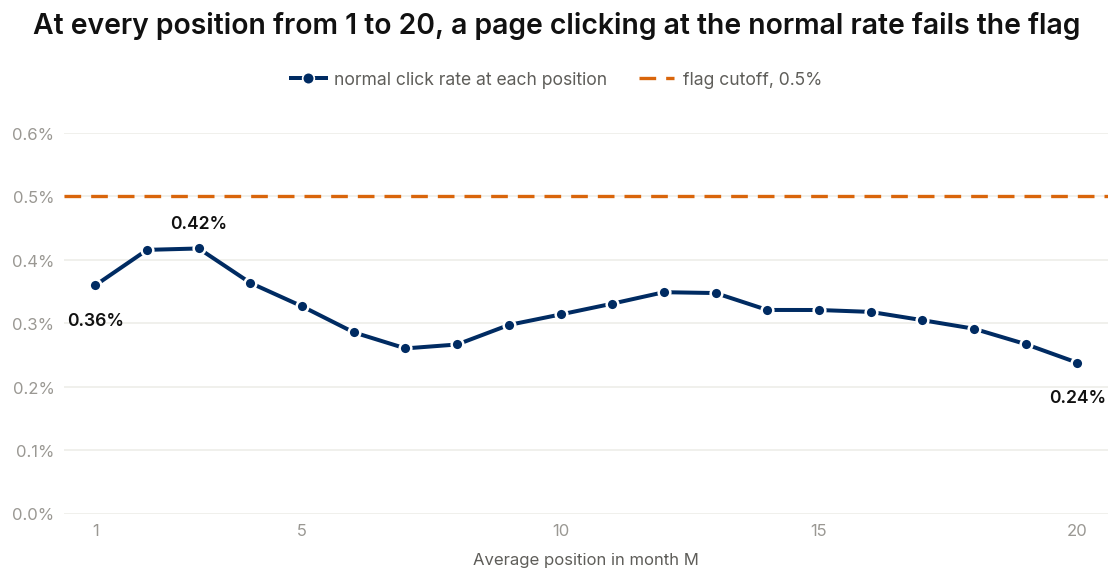

In [11]:
def load_inter() -> str:
    """Register the Inter font for this session and return the font family to draw with.

    The 400 and 600 weights are cached in the system temp folder, never in the project. If the
    download is unavailable, the chart falls back to matplotlib's default font, so the notebook still runs offline.
    """
    cache = os.path.join(tempfile.gettempdir(), "inter-font")
    os.makedirs(cache, exist_ok=True)
    try:
        for weight in (400, 600):
            path = os.path.join(cache, f"inter-{weight}.ttf")
            if not os.path.exists(path):
                urllib.request.urlretrieve(f"https://cdn.jsdelivr.net/fontsource/fonts/inter@latest/latin-{weight}-normal.ttf", path)
            font_manager.fontManager.addfont(path)
    except OSError:
        return "DejaVu Sans"
    return "Inter"


# Emphasis theme: the data in cividis navy, the rule in a darkened orange that passes 3:1 contrast, recessive axes.
INK, MUTED, FAINT, GRID, SURFACE = "#111111", "#5f5e5a", "#9a9893", "#eeede9", "#ffffff"
NAVY, RULE = mpl.colormaps["cividis"](0.05), "#d9650b"
plt.rcParams.update({"font.family": load_inter()})

fig, ax = plt.subplots(figsize=(10, 5.2), dpi=120, facecolor=SURFACE)
fig.subplots_adjust(left=0.09, right=0.96, top=0.74, bottom=0.13)
ax.set_facecolor(SURFACE)
ax.axhline(CUTOFF, color=RULE, linewidth=2, linestyle=(0, (5, 3)), zorder=2)
ax.plot(curve.index, curve["normal_ctr"], color=NAVY, linewidth=2.4, marker="o", markersize=7,
        markerfacecolor=NAVY, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
# Label the first, highest, and last points; a label goes below its point when the line rises away from it.
for rank in sorted({1, int(curve["normal_ctr"].idxmax()), 20} & set(curve.index)):
    value = curve.loc[rank, "normal_ctr"]
    neighbours = curve["normal_ctr"].reindex([rank - 1, rank + 1]).dropna()
    below_line = value < neighbours.mean()
    ax.annotate(f"{value:.2%}", (rank, value), xytext=(0, -16 if below_line else 10), textcoords="offset points", ha="center",
                va="top" if below_line else "bottom", color=INK, fontsize=10.5, fontweight="semibold")

ax.set_xlim(0.4, 20.6)
ax.set_ylim(0, max(curve["normal_ctr"].max(), CUTOFF) * 1.2)
ax.set_xticks([1, 5, 10, 15, 20])
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(xmax=1, decimals=1))
ax.set_xlabel("Average position in month M", color=MUTED, fontsize=10, labelpad=8)
ax.grid(axis="y", color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0, colors=FAINT, labelsize=10, pad=6)
for spine in ax.spines.values():
    spine.set_visible(False)

if len(below) == len(curve):
    title = "At every position from 1 to 20, a page clicking at the normal rate fails the flag"
elif first_below:
    title = f"From position {first_below}, a page clicking at the normal rate already fails the flag"
else:
    title = "The normal click rate stays above the flag's cutoff at every position from 1 to 20"
fig.text(0.5, 0.9, title, ha="center", color=INK, fontsize=17, fontweight="semibold")
key = [Line2D([], [], color=NAVY, linewidth=2.4, marker="o", markersize=7, markeredgecolor=SURFACE, label="normal click rate at each position"),
       Line2D([], [], color=RULE, linewidth=2, linestyle=(0, (5, 3)), label="flag cutoff, 0.5%")]
fig.legend(handles=key, loc="upper center", bbox_to_anchor=(0.5, 0.85), ncol=2, frameon=False, fontsize=10.5,
           labelcolor=MUTED, handletextpad=0.5, columnspacing=1.8, borderaxespad=0)
plt.show()

**Finding:** the whole curve sits under the flag's line. No position from 1 to 20 has a normal click rate that reaches 0.5%, so a page clicking exactly at the normal rate is flagged wherever it ranks.


**Method:** the curve shows what the flag assumes; this cell tests what it achieves. Among pages with 500 or more impressions at positions 1 to 20, it compares how often flagged and unflagged pages fall short next month, inside each position group, and counts the flagged pages that were clicking at or above the normal rate for their position in month M.


In [12]:
# Next-month shortfall rate of flagged and unflagged pages, and flagged pages that were not underperforming at all.
records = []
for name, rows in pairs.items():
    page = rows[(rows["position_m"] < 20.5) & (rows["impressions_m"] >= 500)].copy()
    page["rank"] = page["position_m"].round().clip(lower=1).astype(int)
    page["flagged"] = page["ctr_m"] < CUTOFF
    page["at_or_above_normal"] = page["ctr_m"] >= page["rank"].map(curve["normal_ctr"])
    for position, cell in page.groupby(pd.cut(page["position_m"], POSITION_EDGES, labels=POSITION_NAMES), observed=True):
        row, _ = rate_cells(name, cell, cell["flagged"], ("flagged", "not flagged"))
        flagged = cell[cell["flagged"]]
        records.append({"Pair": name, "Position": position, **row,
                        "Flagged but at or above normal": f"{flagged['at_or_above_normal'].mean():.0%}" if len(flagged) else "none flagged"})
show_table("Does the flag find pages that fall short next month?", pd.DataFrame(records).set_index(["Pair", "Position"]))

**Does the flag find pages that fall short next month?**

| Pair | Position | Pages, flagged | Next-month rate, flagged | Pages, not flagged | Next-month rate, not flagged | Lift | Flagged but at or above normal |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 2026-02 → 2026-03 | 1 to 3 | 7,218 | 24.2% | 2,134 | 1.5% | 15.6x | 8% |
| 2026-02 → 2026-03 | 4 to 10 | 19,193 | 19.3% | 3,670 | 1.8% | 10.5x | 23% |
| 2026-02 → 2026-03 | 11 to 20 | 5,493 | 21.5% | 1,027 | 1.2% | 18.4x | 16% |
| 2026-03 → 2026-04 | 1 to 3 | 7,341 | 23.4% | 2,507 | 3.1% | 7.6x | 9% |
| 2026-03 → 2026-04 | 4 to 10 | 25,251 | 16.2% | 5,455 | 2.0% | 8.2x | 22% |
| 2026-03 → 2026-04 | 11 to 20 | 8,566 | 15.7% | 1,585 | 2.3% | 6.7x | 16% |
| 2026-04 → 2026-05 | 1 to 3 | 3,275 | 7.1% | 1,408 | 1.1% | 6.7x | 8% |
| 2026-04 → 2026-05 | 4 to 10 | 21,538 | 14.8% | 4,857 | 1.3% | 11.0x | 22% |
| 2026-04 → 2026-05 | 11 to 20 | 6,665 | 13.7% | 1,510 | 1.9% | 7.4x | 16% |

**Finding:** the flag is not useless: flagged pages fall short next month 6.7 to 18.4 times as often as unflagged ones. But the comparison is lopsided, because the unflagged pages are the minority that click through at 0.5% or more, far above normal, and rarely fall short. Meanwhile 8% to 23% of the flagged pages were clicking at or above the normal rate for their position, so they were never underperforming at all. The flag works as a coarse filter that sets aside the best-clicking pages, not as a way to pick the pages that most need work.


## 4. What this means in practice

**Method:** this cell collects the four verdicts in one table.


In [13]:
# Every verdict in one place.
show_table("Verdicts at a glance", pd.DataFrame({
    "Claim": ["A shortfall this month predicts one next month", "Buying intent clicks less than informational at the same position",
              "An unstable rank predicts a shortfall next month", "One 0.5% cutoff means underperforming at every position from 1 to 20"],
    "Verdict": [persist_verdict, intent_verdict, volatility_verdict, flag_verdict],
}, index=pd.Index(["Signal #1", "Signal #2", "Signal #3", "Flag-linked test"], name="Test")))

**Verdicts at a glance**

| Test | Claim | Verdict |
| --- | --- | --- |
| Signal #1 | A shortfall this month predicts one next month | CONFIRMED |
| Signal #2 | Buying intent clicks less than informational at the same position | MIXED |
| Signal #3 | An unstable rank predicts a shortfall next month | MIXED |
| Flag-linked test | One 0.5% cutoff means underperforming at every position from 1 to 20 | FALSE |

**Finding:** three things for a content team. **First, shortfalls are worth acting on:** a page that falls clearly short of its expected clicks this month very often does so again next month, so a monthly review queue built on real shortfalls is pointing at lasting problems, not passing noise. **Second, judge a page against its own position and site, not a flat cutoff:** a 0.5% click-through rule flags three quarters or more of all visible pages, including many that click normally for where they rank. **Third, treat common beliefs as hypotheses:** buying-intent keywords did not click less than informational ones, and an unstable rank meant opposite things for small and large pages, so neither belief should drive decisions without the data behind it.


## Limitations

- **Observed, not caused.** A verdict says a pattern appears in these months; it does not say that changing the signal would change the outcome.
- **Four months, three pairs.** Every verdict comes from February to May 2026. A pattern could differ in other seasons.
- **The flag is a stand-in.** FlyRank's real low-CTR rule is not in the release; the tested rule is the starter pipeline's documented version, so the verdict is about that rule's logic.
- **Intent comes from keyword research.** It describes the keyword the page was written for, not every search the page appears in.
- **Signals overlap.** Daily position spread is larger for deeper pages and intent varies by client; the size bands and the client-aware expectation remove the largest overlaps, not all of them.


## Self-check

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
